# پیش‌بینی سادهٔ قیمت بیت‌کوین با LSTM
با ۳۰ روز گذشته، قیمت روز بعد را تخمین می‌زنیم. شبکه یک LSTM با ۱۶ واحد دارد و بازده لگاریتمی را یاد می‌گیرد؛ سپس خروجی به قیمت دلار تبدیل می‌شود.

داده: ستون PriceUSD از [Coin Metrics Community Data](https://github.com/coinmetrics/data)، فایل btc.csv. نسخهٔ استفاده‌شده در `btc_daily.csv` کنار نوت‌بوک ذخیره شده؛ این داده قیمت مرجع روزانه است، نه قیمت زنده یا قیمت بسته‌شدن یک صرافی مشخص.

۷۰٪ آموزش، ۱۵٪ اعتبارسنجی، ۱۵٪ آزمون، به‌ترتیب زمانی. نرمال‌سازی فقط با آموزش انجام می‌شود. ارزیابی یک‌روزجلو است: هر روز از تاریخچهٔ واقعی تا روز قبل استفاده می‌کند، نه پیش‌بینی چندروزهٔ بازگشتی. این نمونهٔ آموزشی تضمینی برای سودآوری ندارد.


اگر کتابخانه‌ها نصب نیستند، یک‌بار اجرا کنید و سپس کرنل را ری‌استارت کنید:
```python
%pip install tensorflow==2.20.0 numpy==1.26.4 pandas==2.2.3 matplotlib==3.10.1 scipy==1.14.1 scikit-learn==1.5.2
```
فایل `btc_daily.csv` را کنار نوت‌بوک بگذارید و Run All بزنید. خروجی‌های همین نسخه قبلاً اجرا و ذخیره شده‌اند.


In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display

tf.keras.utils.set_random_seed(42)
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
print('TensorFlow:', tf.__version__)


TensorFlow: 2.20.0


In [2]:
df = pd.read_csv('btc_daily.csv', parse_dates=['date']).sort_values('date').reset_index(drop=True)
assert df.date.is_unique and df.price_usd.gt(0).all()
assert df.date.diff().dropna().eq(pd.Timedelta(days=1)).all(), 'داده باید روزانه و بدون فاصله باشد'
print(f'{len(df)} daily prices: {df.date.min().date()} to {df.date.max().date()}')
display(df.tail())


2335 daily prices: 2020-01-01 to 2026-05-23


,date,price_usd
2330,2026-05-19,76807.460956
2331,2026-05-20,77408.172209
2332,2026-05-21,77595.386172
2333,2026-05-22,75567.543043
2334,2026-05-23,76619.866609


In [3]:
window = 30
prices = df.price_usd.to_numpy()
returns = np.diff(np.log(prices))
# هدف returns[t] مربوط به قیمت روز t+1 است؛ ورودی فقط روزهای قبل را دارد.
targets = np.arange(window, len(returns))
a, b = int(len(targets)*0.70), int(len(targets)*0.85)
mu, sigma = returns[:targets[a]].mean(), returns[:targets[a]].std()
z = ((returns-mu)/sigma).astype('float32')
X = np.array([z[t-window:t] for t in targets])[..., None]
y = z[targets]
X_train, X_val, X_test = X[:a], X[a:b], X[b:]
y_train, y_val, y_test = y[:a], y[a:b], y[b:]
print('Train / validation / test:', len(y_train), len(y_val), len(y_test))
print('Test dates:', df.date.iloc[targets[b]+1].date(), 'to', df.date.iloc[-1].date())


Train / validation / test: 1612 346 346
Test dates: 2025-06-12 to 2026-05-23


In [4]:
def batches(x, y):
    ds = tf.data.Dataset.from_tensor_slices((x, y)).batch(32)
    opts = tf.data.Options()
    opts.threading.private_threadpool_size = 1
    return ds.with_options(opts)

model = tf.keras.Sequential([
    tf.keras.layers.Input((window, 1)),
    tf.keras.layers.LSTM(16),
    tf.keras.layers.Dense(1)
])
model.compile(optimizer='adam', loss='mse')
model.summary()
history = model.fit(
    batches(X_train, y_train), validation_data=batches(X_val, y_val),
    epochs=20, verbose=2,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)]
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,169 (4.57 KB)

 Trainable params: 1,169 (4.57 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


... (36 outputs left out)

Epoch 19/20


51/51 - 0s - 4ms/step - loss: 0.9818 - val_loss: 0.5593


Epoch 20/20


51/51 - 0s - 3ms/step - loss: 0.9803 - val_loss: 0.5593


,MAE (USD),RMSE (USD),MAPE (%)
LSTM,1434.51,1944.84,1.57
Previous-day baseline,1435.02,1950.63,1.58


LSTM beats baseline on MAE: True


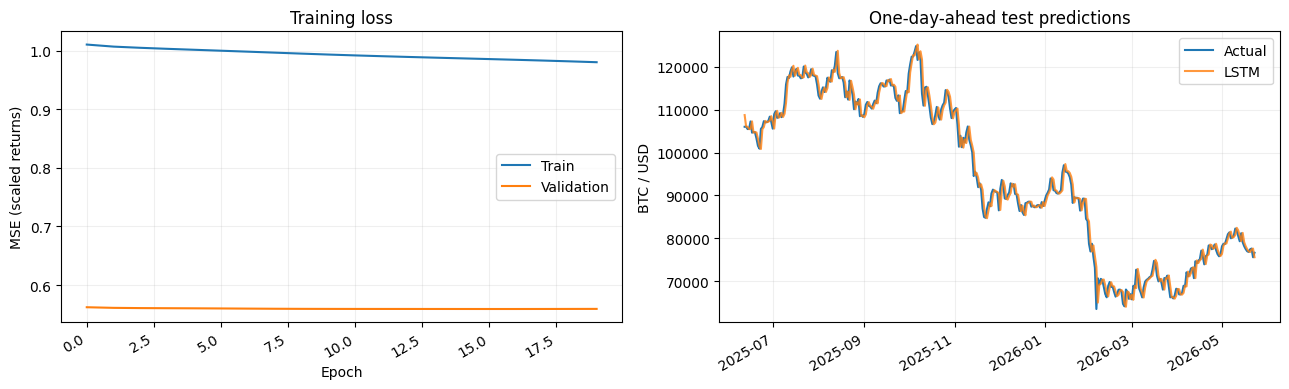

In [5]:
pred_return = model(X_test, training=False).numpy().ravel()*sigma + mu
previous = prices[targets[b:]]
actual = prices[targets[b:]+1]
predicted = previous * np.exp(pred_return)
assert np.isfinite(predicted).all()
metrics = pd.DataFrame({
    name: {'MAE (USD)': np.mean(np.abs(actual-p)),
           'RMSE (USD)': np.sqrt(np.mean((actual-p)**2)),
           'MAPE (%)': np.mean(np.abs((actual-p)/actual))*100}
    for name, p in [('LSTM', predicted), ('Previous-day baseline', previous)]
}).T
display(metrics.round(2))
print('LSTM beats baseline on MAE:', bool(metrics.iloc[0,0] < metrics.iloc[1,0]))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(history.history['loss'], label='Train')
ax[0].plot(history.history['val_loss'], label='Validation')
ax[0].set(title='Training loss', xlabel='Epoch', ylabel='MSE (scaled returns)')
ax[1].plot(df.date.iloc[targets[b:]+1], actual, label='Actual')
ax[1].plot(df.date.iloc[targets[b:]+1], predicted, label='LSTM', alpha=.8)
ax[1].set(title='One-day-ahead test predictions', ylabel='BTC / USD')
for axis in ax: axis.legend(); axis.grid(alpha=.2)
fig.autofmt_xdate(); plt.tight_layout(); plt.show()


In [6]:
last_window = z[-window:][None, ..., None]
next_return = float(model(last_window, training=False).numpy()[0,0])*sigma + mu
next_price = float(prices[-1] * np.exp(next_return))
next_date = df.date.iloc[-1] + pd.Timedelta(days=1)
print(f'Last observed: {df.date.iloc[-1].date()} | ${prices[-1]:,.2f}')
print(f'LSTM estimate for {next_date.date()}: ${next_price:,.2f}')
print('This forecast is relative to the last dataset date, not a live forecast.')
display(pd.DataFrame({'date': df.date.iloc[targets[b:]+1].to_numpy(),
                      'actual_usd': actual, 'predicted_usd': predicted}).tail().round(2))


Last observed: 2026-05-23 | $76,619.87
LSTM estimate for 2026-05-24: $76,555.74
This forecast is relative to the last dataset date, not a live forecast.


,date,actual_usd,predicted_usd
341,2026-05-19,76807.46,76945.46
342,2026-05-20,77408.17,76775.41
343,2026-05-21,77595.39,77371.67
344,2026-05-22,75567.54,77582.16
345,2026-05-23,76619.87,75575.64


### برداشت از این اجرا
در آزمون ۳۴۶ روزه، MAE مدل حدود ۱۴۳۴٫۵۱ دلار و خط پایه ۱۴۳۵٫۰۲ دلار است. اختلاف حدود نیم دلار است و مزیت قابل اتکایی را اثبات نمی‌کند. خطای درصدی گزارش‌شده MAPE است، نه درصد دقت. تخمین ۲۴ مهٔ ۲۰۲۶ صرفاً ادامهٔ این نسخهٔ داده است؛ پیش‌بینی زندهٔ امروز نیست.
